In [ ]:
#Import Dataset
from google.colab import files
uploaded = files.upload()

Saving Telco Customer Churn.csv to Telco Customer Churn.csv


In [ ]:
import pandas as pd
data = pd.read_csv('Telco Customer Churn.csv')
data

,customerID,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,7590-VHVEG,Female,1,DSL,Month-to-month,29.85,No,No,No
1,5575-GNVDE,Male,34,DSL,One year,56.95,Yes,No,No
2,3668-QPYBK,Male,2,DSL,Month-to-month,53.85,Yes,No,Yes
3,7795-CFOCW,Male,45,DSL,One year,42.30,Yes,Yes,No
4,9237-HQITU,Female,2,Fiber optic,Month-to-month,70.70,No,No,Yes
...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,24,DSL,One year,84.80,Yes,Yes,No
7039,2234-XADUH,Female,72,Fiber optic,One year,103.20,No,No,No
7040,4801-JZAZL,Female,11,DSL,Month-to-month,29.60,Yes,No,No
7041,8361-LTMKD,Male,4,Fiber optic,Month-to-month,74.40,No,No,Yes


Preprocessing

In [ ]:
# Cek missing value
data.isna().sum()

,0
customerID,0
gender,0
tenure,0
InternetService,0
Contract,0
MonthlyCharges,0
OnlineSecurity,0
TechSupport,0
Churn,0


In [ ]:
# Cek jumlah baris yang duplikat
data.duplicated().sum()

np.int64(0)

In [ ]:
for column in data.columns:
    print(f"Unique values for column '{column}':")
    print(data[column].unique())
    print("\n")

Unique values for column 'customerID':
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']


Unique values for column 'gender':
['Female' 'Male']


Unique values for column 'tenure':
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]


Unique values for column 'InternetService':
['DSL' 'Fiber optic' 'No']


Unique values for column 'Contract':
['Month-to-month' 'One year' 'Two year']


Unique values for column 'MonthlyCharges':
[29.85 56.95 53.85 ... 63.1  44.2  78.7 ]


Unique values for column 'OnlineSecurity':
['No' 'Yes' 'No internet service']


Unique values for column 'TechSupport':
['No' 'Yes' 'No internet service']


Unique values for column 'Churn':
['No' 'Yes']




In [ ]:
# Mengubah kolom 'gender' menjadi numerik
data['gender'] = data['gender'].map({'Male': 0, 'Female': 1})
data

,customerID,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,7590-VHVEG,1,1,DSL,Month-to-month,29.85,No,No,No
1,5575-GNVDE,0,34,DSL,One year,56.95,Yes,No,No
2,3668-QPYBK,0,2,DSL,Month-to-month,53.85,Yes,No,Yes
3,7795-CFOCW,0,45,DSL,One year,42.30,Yes,Yes,No
4,9237-HQITU,1,2,Fiber optic,Month-to-month,70.70,No,No,Yes
...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,24,DSL,One year,84.80,Yes,Yes,No
7039,2234-XADUH,1,72,Fiber optic,One year,103.20,No,No,No
7040,4801-JZAZL,1,11,DSL,Month-to-month,29.60,Yes,No,No
7041,8361-LTMKD,0,4,Fiber optic,Month-to-month,74.40,No,No,Yes


In [ ]:
# Mengubah kolom 'InternetService' menjadi numerik
data['InternetService'] = data['InternetService'].map({'DSL': 0, 'Fiber optic': 1, 'No': 2})
data

,customerID,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,7590-VHVEG,1,1,0,Month-to-month,29.85,No,No,No
1,5575-GNVDE,0,34,0,One year,56.95,Yes,No,No
2,3668-QPYBK,0,2,0,Month-to-month,53.85,Yes,No,Yes
3,7795-CFOCW,0,45,0,One year,42.30,Yes,Yes,No
4,9237-HQITU,1,2,1,Month-to-month,70.70,No,No,Yes
...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,24,0,One year,84.80,Yes,Yes,No
7039,2234-XADUH,1,72,1,One year,103.20,No,No,No
7040,4801-JZAZL,1,11,0,Month-to-month,29.60,Yes,No,No
7041,8361-LTMKD,0,4,1,Month-to-month,74.40,No,No,Yes


In [ ]:
# Mengubah kolom 'Contract' menjadi numerik
data['Contract'] = data['Contract'].map({'One year': 0, 'Two year': 1, 'Month-to-month': 2})
data

,customerID,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,7590-VHVEG,1,1,0,2,29.85,No,No,No
1,5575-GNVDE,0,34,0,0,56.95,Yes,No,No
2,3668-QPYBK,0,2,0,2,53.85,Yes,No,Yes
3,7795-CFOCW,0,45,0,0,42.30,Yes,Yes,No
4,9237-HQITU,1,2,1,2,70.70,No,No,Yes
...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,24,0,0,84.80,Yes,Yes,No
7039,2234-XADUH,1,72,1,0,103.20,No,No,No
7040,4801-JZAZL,1,11,0,2,29.60,Yes,No,No
7041,8361-LTMKD,0,4,1,2,74.40,No,No,Yes


In [ ]:
# Mengubah kolom 'OnlineSecurity' menjadi numerik
data['OnlineSecurity'] = data['OnlineSecurity'].map({'No': 0, 'Yes': 1, 'No internet service': 2})
data

,customerID,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,7590-VHVEG,1,1,0,2,29.85,0,No,No
1,5575-GNVDE,0,34,0,0,56.95,1,No,No
2,3668-QPYBK,0,2,0,2,53.85,1,No,Yes
3,7795-CFOCW,0,45,0,0,42.30,1,Yes,No
4,9237-HQITU,1,2,1,2,70.70,0,No,Yes
...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,24,0,0,84.80,1,Yes,No
7039,2234-XADUH,1,72,1,0,103.20,0,No,No
7040,4801-JZAZL,1,11,0,2,29.60,1,No,No
7041,8361-LTMKD,0,4,1,2,74.40,0,No,Yes


In [ ]:
# Mengubah kolom 'TechSupport' menjadi numerik
data['TechSupport'] = data['TechSupport'].map({'No': 0, 'Yes': 1, 'No internet service': 2})
data

,customerID,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,7590-VHVEG,1,1,0,2,29.85,0,0,No
1,5575-GNVDE,0,34,0,0,56.95,1,0,No
2,3668-QPYBK,0,2,0,2,53.85,1,0,Yes
3,7795-CFOCW,0,45,0,0,42.30,1,1,No
4,9237-HQITU,1,2,1,2,70.70,0,0,Yes
...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,24,0,0,84.80,1,1,No
7039,2234-XADUH,1,72,1,0,103.20,0,0,No
7040,4801-JZAZL,1,11,0,2,29.60,1,0,No
7041,8361-LTMKD,0,4,1,2,74.40,0,0,Yes


In [ ]:
# Mengubah kolom 'Churn' menjadi numerik
data['Churn'] = data['Churn'].map({'No': 0, 'Yes': 1})
data

,customerID,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,7590-VHVEG,1,1,0,2,29.85,0,0,0
1,5575-GNVDE,0,34,0,0,56.95,1,0,0
2,3668-QPYBK,0,2,0,2,53.85,1,0,1
3,7795-CFOCW,0,45,0,0,42.30,1,1,0
4,9237-HQITU,1,2,1,2,70.70,0,0,1
...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,24,0,0,84.80,1,1,0
7039,2234-XADUH,1,72,1,0,103.20,0,0,0
7040,4801-JZAZL,1,11,0,2,29.60,1,0,0
7041,8361-LTMKD,0,4,1,2,74.40,0,0,1


In [ ]:
# Drop Customer ID
data.drop(columns=['customerID'], inplace=True)
data

,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,1,1,0,2,29.85,0,0,0
1,0,34,0,0,56.95,1,0,0
2,0,2,0,2,53.85,1,0,1
3,0,45,0,0,42.30,1,1,0
4,1,2,1,2,70.70,0,0,1
...,...,...,...,...,...,...,...,...
7038,0,24,0,0,84.80,1,1,0
7039,1,72,1,0,103.20,0,0,0
7040,1,11,0,2,29.60,1,0,0
7041,0,4,1,2,74.40,0,0,1


In [ ]:
datafinal = data.copy()

display(datafinal.head())

,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
0,1,1,0,2,29.85,0,0,0
1,0,34,0,0,56.95,1,0,0
2,0,2,0,2,53.85,1,0,1
3,0,45,0,0,42.30,1,1,0
4,1,2,1,2,70.70,0,0,1


##EKSPLORASI DATA

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display descriptive statistics
print("Descriptive Statistics:")
display(datafinal.describe())


Descriptive Statistics:


,gender,tenure,InternetService,Contract,MonthlyCharges,OnlineSecurity,TechSupport,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.495244,32.371149,0.872923,1.341048,64.761692,0.720006,0.723555,0.265370
std,0.500013,24.559481,0.737796,0.801943,30.090047,0.796885,0.795896,0.441561
min,0.000000,0.000000,0.000000,0.000000,18.250000,0.000000,0.000000,0.000000
25%,0.000000,9.000000,0.000000,1.000000,35.500000,0.000000,0.000000,0.000000
50%,0.000000,29.000000,1.000000,2.000000,70.350000,1.000000,1.000000,0.000000
75%,1.000000,55.000000,1.000000,2.000000,89.850000,1.000000,1.000000,1.000000
max,1.000000,72.000000,2.000000,2.000000,118.750000,2.000000,2.000000,1.000000


Let's visualize the distribution of the target variable, 'Churn'.

/tmp/ipython-input-1655868956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=datafinal, palette='viridis')


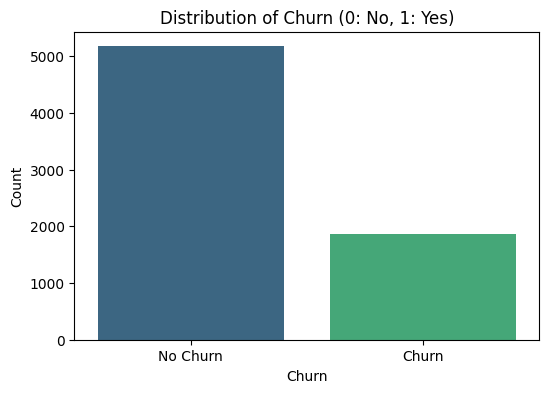


Churn Value Counts:


,count
Churn,
0,5174
1,1869


In [ ]:
# Visualize 'Churn' distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=datafinal, palette='viridis')
plt.title('Distribution of Churn (0: No, 1: Yes)')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.show()

print("\nChurn Value Counts:")
display(datafinal['Churn'].value_counts())


Now, let's explore the distribution of numerical features like 'tenure' and 'MonthlyCharges', and their relationship with 'Churn'.

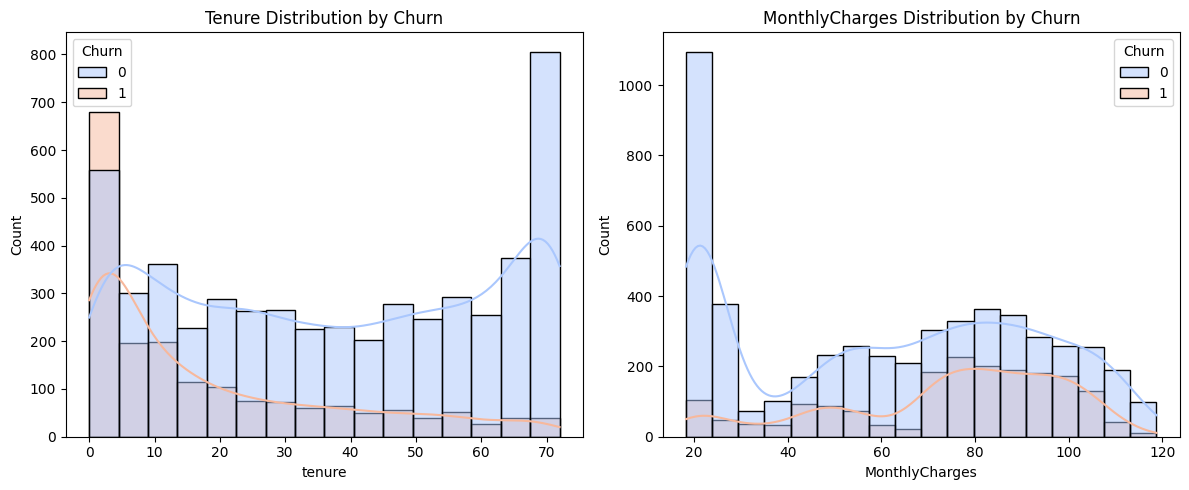

In [ ]:
# Visualize distribution of 'tenure' and 'MonthlyCharges' by 'Churn'
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=datafinal, x='tenure', hue='Churn', kde=True, palette='coolwarm')
plt.title('Tenure Distribution by Churn')

plt.subplot(1, 2, 2)
sns.histplot(data=datafinal, x='MonthlyCharges', hue='Churn', kde=True, palette='coolwarm')
plt.title('MonthlyCharges Distribution by Churn')

plt.tight_layout()
plt.show()


Next, let's look at the distribution of categorical features and their impact on 'Churn'.

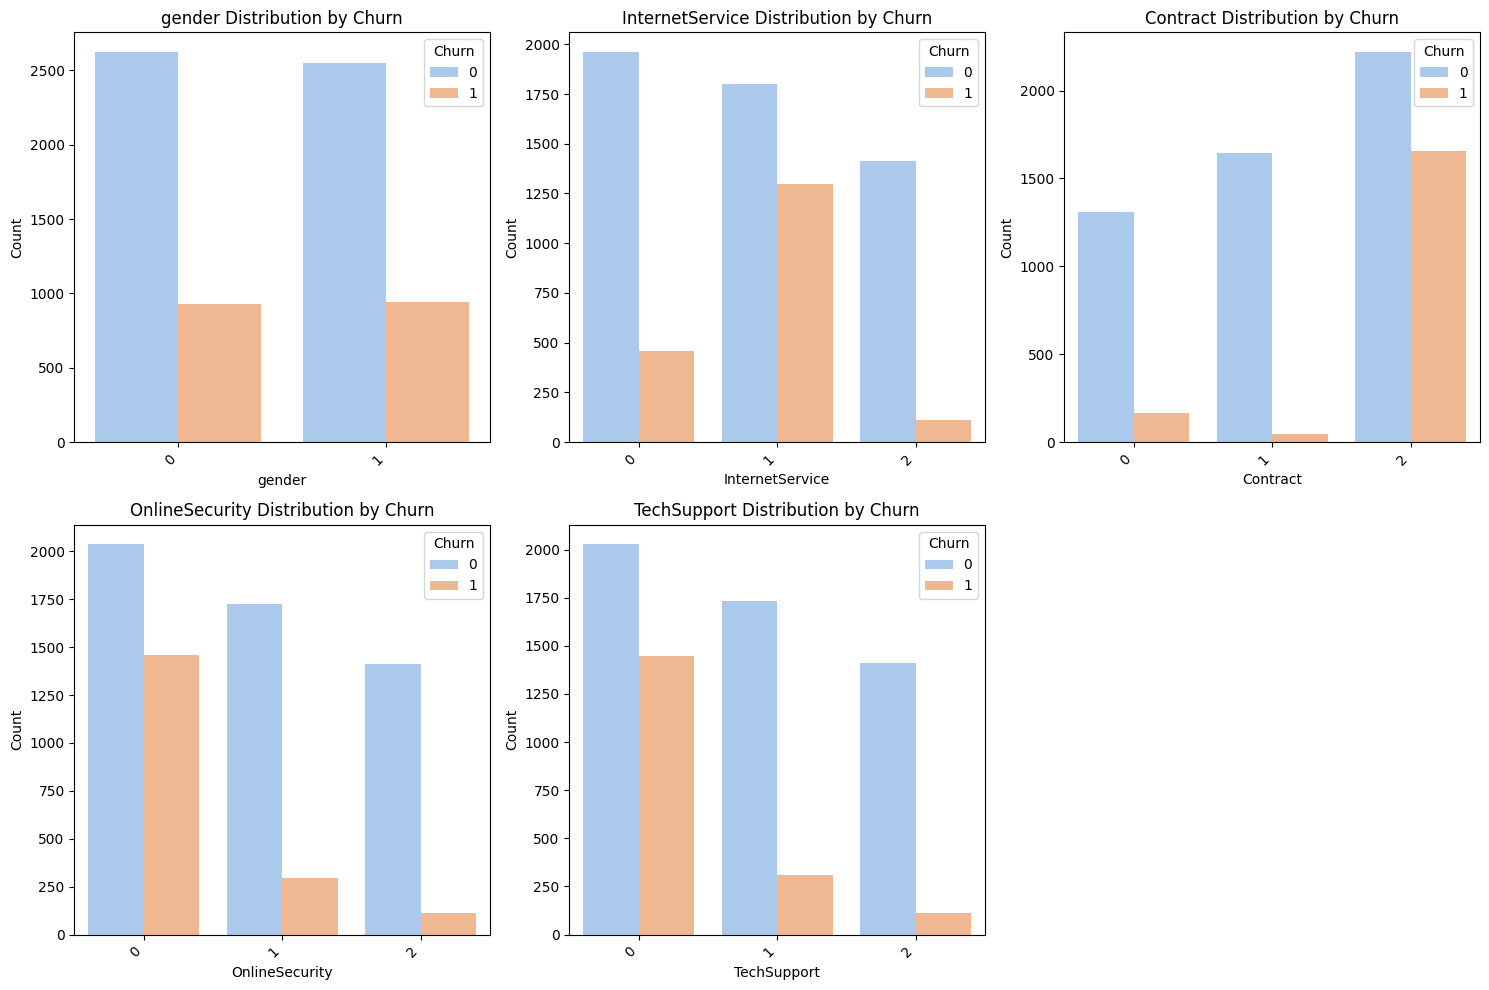

In [ ]:
# Visualize categorical features against 'Churn'
categorical_features = ['gender', 'InternetService', 'Contract', 'OnlineSecurity', 'TechSupport']

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_features):
    plt.subplot(2, 3, i + 1) # Adjust subplot grid as needed
    sns.countplot(data=datafinal, x=col, hue='Churn', palette='pastel')
    plt.title(f'{col} Distribution by Churn')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


Pemodelan Naive Bayes

In [ ]:
# Import library
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Library Naive Bayes
from sklearn.naive_bayes import GaussianNB # Asumsi berdistribusi normal
#from sklearn.naive_bayes import MultinomialNB
#from sklearn.naive_bayes import BernoulliNB

In [ ]:
# Menentukan fitur (X) dan target (Y)
# 'Churn' is the target variable for classification.

X = datafinal[['gender', 'tenure', 'InternetService', 'Contract', 'MonthlyCharges', 'OnlineSecurity', 'TechSupport']].values
Y = datafinal['Churn'].values

In [ ]:
# Membagi data menjadi data training dan data testing (70% training, 30% testing)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=41)

Prior Sesuai Jumlah Kategori Respons

In [ ]:
# Membangun dan melatih model Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train,Y_train)

GaussianNB()

In [ ]:
# Melihat daftar kelas
gnb.classes_

array([0, 1])

In [ ]:
# Melihat probabilitas prior tiap kelas
gnb.class_prior_

array([0.73427992, 0.26572008])

In [ ]:
# Melihat jumlah data di setiap kelas
gnb.class_count_

array([3620., 1310.])

In [ ]:
# Mean tiap fitur untuk setiap kelas
gnb.theta_

array([[ 0.49502762, 38.26491713,  0.89226519,  1.17651934, 61.73469613,
         0.87651934,  0.88314917],
       [ 0.49083969, 17.92442748,  0.81526718,  1.79923664, 74.52217557,
         0.26564885,  0.29007634]])

In [ ]:
# Variance tiap fitur untuk setiap kelas
gnb.var_

array([[2.49976189e-01, 5.86184792e+02, 6.35355451e-01, 6.44808688e-01,
        9.82512966e+02, 6.47460622e-01, 6.42424146e-01],
       [2.49917002e-01, 3.77407267e+02, 2.66638056e-01, 3.37557583e-01,
        6.03298419e+02, 3.11110989e-01, 3.21963503e-01]])

In [ ]:
# Probabilitas tiap kelas untuk data testing
y_prob_gnb = gnb.predict_proba(X_test)

# Hasil prediksi kelas akhir
y_pred_gnb = gnb.predict(X_test)

In [ ]:
# Ambil nama kelas dari model
kelas = gnb.classes_

# Membuat dataframe dari probabilitas
predict = pd.DataFrame(y_prob_gnb, columns=[f'Prob_{c}' for c in kelas])

# Menambahkan kolom hasil prediksi
predict['Prediksi'] = y_pred_gnb
predict

,Prob_0,Prob_1,Prediksi
0,0.982549,0.017451,0
1,0.983614,0.016386,0
2,0.318906,0.681094,1
3,0.999797,0.000203,0
4,0.042828,0.957172,1
...,...,...,...
2108,0.999791,0.000209,0
2109,0.993083,0.006917,0
2110,0.245461,0.754539,1
2111,0.978413,0.021587,0


In [ ]:
# Confusion Matrix
cf_gnb =  confusion_matrix(Y_test, y_pred_gnb)
print("Confusion Matrix:")
cf_gnb

Confusion Matrix:


array([[1106,  448],
       [ 124,  435]])

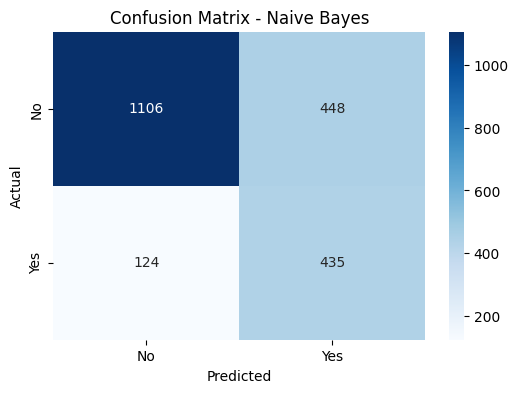

In [ ]:
# Nama label untuk sumbu
target_names = ['No', 'Yes']

# Plot confusion matrix dengan heatmap
plt.figure(figsize=(6,4))
sns.heatmap(cf_gnb, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names,
            yticklabels=target_names)
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Classification Report
cr_gnb = classification_report(Y_test, y_pred_gnb, labels=[0,1],
                               target_names=target_names, output_dict=True)

# Mengubah menjadi dataframe
df_cr_gnb = pd.DataFrame(cr_gnb)
df_cr_gnb

,No,Yes,accuracy,macro avg,weighted avg
precision,0.899187,0.492639,0.729295,0.695913,0.791634
recall,0.711712,0.778175,0.729295,0.744944,0.729295
f1-score,0.794540,0.603329,0.729295,0.698934,0.743955
support,1554.000000,559.000000,0.729295,2113.000000,2113.000000


### Prior dengan Pembagian Kategori secara Merata

In [ ]:
# Membangun dan melatih model Gaussian Naive Bayes
gnb_1 = GaussianNB(priors=[1/2,1/2])
gnb_1.fit(X_train,Y_train)

GaussianNB(priors=[0.5, 0.5])

In [ ]:
# Melihat daftar kelas
gnb_1.classes_

array([0, 1])

In [ ]:
# Melihat probabilitas prior tiap kelas
gnb_1.class_prior_

array([0.5, 0.5])

In [ ]:
# Melihat jumlah data di setiap kelas
gnb_1.class_count_

array([3620., 1310.])

In [ ]:
# Mean tiap fitur untuk setiap kelas
gnb_1.theta_

array([[ 0.49502762, 38.26491713,  0.89226519,  1.17651934, 61.73469613,
         0.87651934,  0.88314917],
       [ 0.49083969, 17.92442748,  0.81526718,  1.79923664, 74.52217557,
         0.26564885,  0.29007634]])

In [ ]:
# Variance tiap fitur untuk setiap kelas
gnb_1.var_

array([[2.49976189e-01, 5.86184792e+02, 6.35355451e-01, 6.44808688e-01,
        9.82512966e+02, 6.47460622e-01, 6.42424146e-01],
       [2.49917002e-01, 3.77407267e+02, 2.66638056e-01, 3.37557583e-01,
        6.03298419e+02, 3.11110989e-01, 3.21963503e-01]])

In [ ]:
# Probabilitas tiap kelas untuk data testing
y_prob_gnb_1 = gnb_1.predict_proba(X_test)

# Hasil prediksi kelas akhir
y_pred_gnb_1 = gnb_1.predict(X_test)

In [ ]:
# Ambil nama kelas dari model
kelas = gnb_1.classes_

# Membuat dataframe dari probabilitas
predict = pd.DataFrame(y_prob_gnb_1, columns=[f'Prob_{c}' for c in kelas])

# Menambahkan kolom hasil prediksi
predict['Prediksi'] = y_pred_gnb_1
predict

,Prob_0,Prob_1,Prediksi
0,0.953216,0.046784,0
1,0.955992,0.044008,0
2,0.144890,0.855110,1
3,0.999440,0.000560,0
4,0.015934,0.984066,1
...,...,...,...
2108,0.999423,0.000577,0
2109,0.981115,0.018885,0
2110,0.105325,0.894675,1
2111,0.942534,0.057466,0


In [ ]:
# Confusion Matrix
cf_gnb_1 =  confusion_matrix(Y_test, y_pred_gnb_1)
print("Confusion Matrix:")
cf_gnb_1

Confusion Matrix:


array([[1018,  536],
       [ 103,  456]])

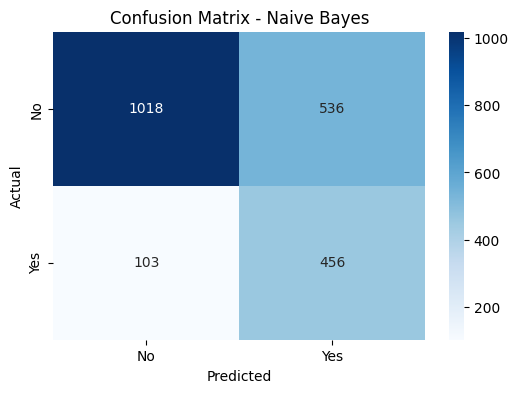

In [ ]:
# Nama label untuk sumbu
target_names = ['No', 'Yes']

# Plot confusion matrix dengan heatmap
plt.figure(figsize=(6,4))
sns.heatmap(cf_gnb_1, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names,
            yticklabels=target_names)
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Classification Report
cr_gnb_1 = classification_report(Y_test, y_pred_gnb_1, labels=[0,1],
                                 target_names=target_names, output_dict=True)

# Mengubah menjadi dataframe
df_cr_gnb_1 = pd.DataFrame(cr_gnb_1)
df_cr_gnb_1

,No,Yes,accuracy,macro avg,weighted avg
precision,0.908118,0.459677,0.697586,0.683898,0.789482
recall,0.655084,0.815742,0.697586,0.735413,0.697586
f1-score,0.761121,0.588008,0.697586,0.674565,0.715324
support,1554.000000,559.000000,0.697586,2113.000000,2113.000000
